# Cardiovascular risk prediction: walkthrough

I built a 10-year cardiovascular mortality risk model on NHANES 1999–2018 linked to the National Death Index (23,888 US adults) and benchmarked it against the clinical standard, the ACC/AHA Pooled Cohort Equations. On a later test period it reaches ROC-AUC 0.822 (PCE 0.799) with near-perfect calibration (observed/expected 1.01 vs 0.26), and the top 10% by risk captures 47% of cardiovascular deaths.

| Part | Question | Data |
|---|---|---|
| **1** | My earlier 918-patient heart-disease classifier: was it evaluated correctly, and does it work at a hospital it never saw? | UCI Heart Disease, 4 hospitals (918 patients) |
| **2** | The model: can routinely measured risk factors predict **10-year death from cardiovascular disease** better than the Pooled Cohort Equations? | NHANES 1999–2018 linked to the National Death Index (23,888 adults) |

Every cell runs on files in this repository. The NHANES cohort is public-domain data and is committed. Part 1's exact 918-row file comes from Kaggle and isn't redistributed (see `data/README.md`). Without it, the Part 1 cells use the UCI hospital files, and the saved outputs below show the run on the 918 rows.

In [1]:
import json, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

ROOT = Path("..") if (Path("..") / "results").exists() else Path("Cardiovascular-Risk-Prediction")
if not (ROOT / "results").exists():          # opened on its own (e.g. in Colab): fetch the repository
    subprocess.run(["git", "clone", "-q", "https://github.com/Muneera-DSA/Cardiovascular-Risk-Prediction.git"], check=True)
sys.path.insert(0, str(ROOT / "src"))
from cvd_risk import config, pce, uci, audit918
RES, FIG = ROOT / "results", ROOT / "reports" / "figures"
R = lambda name: json.loads((RES / f"{name}.json").read_text())
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 200)
print("results:", sorted(p.name for p in RES.glob("*.json")))

results: ['benchmark.json', 'benchmark_extra.json', 'cohort_build.json', 'download_manifest.json', 'eda.json', 'explain.json', 'imbalance.json', 'leakage.json', 'part1_audit.json', 'part1_extra.json', 'quality.json', 'select.json', 'subgroups.json', 'survival.json', 'temporal.json']


---
## Part 1: auditing the original 918-patient notebook

### 1a. Data validation

In [2]:
kaggle = ROOT / "data" / "heart_failure_918.csv"
heart = audit918.load(kaggle if kaggle.exists() else None, ROOT / "data" / "uci_heart_4_hospitals.csv")
print(f"{len(heart)} patients ({'Kaggle 918-row file, hospital attached by matching' if kaggle.exists() else 'UCI hospital files'})")
q = audit918.quality(heart)
print({k: v for k, v in q.items() if k not in ("by_site",)})
display(pd.DataFrame(q["by_site"]).round(3))

918 patients (Kaggle 918-row file, hospital attached by matching)
{'rows': 918, 'columns': 12, 'missing_values': 0, 'exact_duplicates': 0, 'cholesterol_zero': 172, 'resting_bp_zero': 1, 'oldpeak_negative': 13, 'disease_rate': 0.5533769063180828, 'site_matched': 918, 'site_assignment': {'exact match': 916, 'neighbouring rows (ambiguous match)': 2}}


,site,patients,disease_rate,cholesterol_zero,resting_bp_zero
0,Cleveland (USA),303,0.459,0.000,0.000
1,Budapest (Hungary),293,0.362,0.000,0.000
2,Zurich & Basel (Switzerland),123,0.935,1.000,0.000
3,Long Beach VA (USA),199,0.744,0.246,0.005


**What this shows**
- No cells are blank, but **172 patients have cholesterol = 0** and one has resting blood pressure = 0. Neither is possible in a living patient, so these are missing values recorded as 0.
- Every Swiss patient has cholesterol 0, and 93% of them have heart disease. The four hospitals differ hugely in disease rate (36% to 93%), so the data is a mix of very different referral populations.

{
 "disease_rate_when_cholesterol_zero": 0.8837209302325582,
 "disease_rate_when_measured": 0.4772117962466488,
 "auc_of_the_zero_flag_alone": 0.6252160553101593,
 "mean_cholesterol_by_class_with_zeros": {
  "0": 227.1219512195122,
  "1": 175.94094488188978
 },
 "mean_cholesterol_by_class_measured_only": {
  "0": 238.76923076923077,
  "1": 251.06179775280899
 },
 "measured_only_mannwhitney_p": 0.0017130070426659358,
 "zeros_by_site": {
  "switzerland": 123,
  "va": 49
 }
}


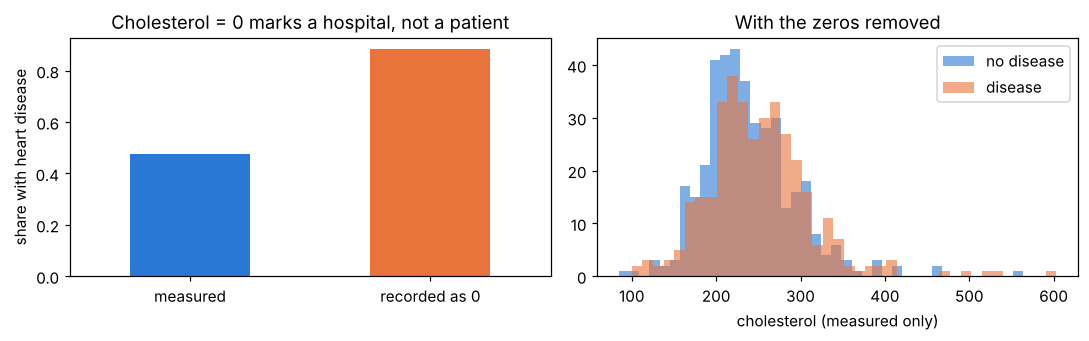

In [3]:
sh = audit918.cholesterol_shortcut(heart)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
d = heart.assign(chol_zero=np.where(heart.Cholesterol == 0, "recorded as 0", "measured"))
d.groupby("chol_zero").HeartDisease.mean().plot.bar(ax=ax[0], color=["#2a78d6", "#e8743b"], rot=0)
ax[0].set(ylabel="share with heart disease", xlabel="", title="Cholesterol = 0 marks a hospital, not a patient")
m = heart[heart.Cholesterol > 0]
for y, c in ((0, "#2a78d6"), (1, "#e8743b")):
    ax[1].hist(m.loc[m.HeartDisease == y, "Cholesterol"], bins=40, alpha=0.6, color=c, label=["no disease", "disease"][y])
ax[1].set(xlabel="cholesterol (measured only)", title="With the zeros removed"); ax[1].legend()
plt.tight_layout(); plt.show()
print(json.dumps(sh, indent=1))

The original notebook reported that heart patients have *lower* cholesterol (176 vs 227). That was an artefact of the zeros. Among patients whose cholesterol was actually measured, those with heart disease have *higher* cholesterol, as medicine expects.

### 1b. The original pipeline, reproduced exactly
Same encoding, split (`random_state=10`, stratified), scaling and models as the notebook.

In [4]:
a1 = R("part1_audit")
orig = pd.DataFrame(a1["original_pipeline"]["models"])
display(orig.round(3))
print("final 'best classifier' cell:", a1["original_pipeline"]["final_cell_bug"])

,model,cv_train_auc,cv_auc,notebook_test_score (AUC of 0/1 predictions),balanced_accuracy,test_auc (probabilities),test_auc_ci
0,LogisticRegression,0.931,0.922,0.888,0.888,0.935,"[0.897826758032453, 0.9725701812310572]"
1,KNeighborsClassifier,0.962,0.904,0.861,0.861,0.914,"[0.8704898281210235, 0.9575828643706074]"
2,DecisionTreeClassifier,1.000,0.777,0.786,0.786,0.786,"[0.7260279505464083, 0.8461863010078717]"
3,RandomForestClassifier,1.000,0.921,0.900,0.900,0.943,"[0.9098837278797903, 0.9768929340044753]"
4,SVC,0.961,0.926,0.900,0.900,0.931,"[0.8916315968624929, 0.9711135011767228]"
5,XGBClassifier,1.000,0.913,0.902,0.902,0.938,"[0.9012104623434094, 0.9754035979148401]"


final 'best classifier' cell: {'columns_used': ['Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up'], 'cv_accuracy_dummies_only': 0.8556425309849967, 'cv_accuracy_all_features': 0.8569844376106607}


**Three findings**
1. **The "test_score" was not ROC-AUC.** The notebook passed 0/1 predictions to `roc_auc_score`, which returns balanced accuracy (the two columns are identical). The real test ROC-AUC, from probabilities, is 0.93–0.94 for logistic regression, random forest, SVM and XGBoost (the notebook's XGBoost was rerun on Colab with xgboost 3.4, so its numbers differ slightly from the original run).
2. **The final "best model" cell trained on the wrong columns.** `X_train` had already been overwritten with the 9 dummy columns. This reproduces the notebook's 0.8556 exactly. Using all features changes the score very little (0.857), because the categorical features carry most of the signal. So the bug made the analysis wrong but barely changed the number.
3. **The test set was reused to compare and tune models.** With only 184 test patients, the 95% intervals overlap almost completely, so the ranking between models is noise.

### 1c. Class balance
55% of patients have heart disease, so the classes are close to balanced overall, but the rate ranges from 36% to 93% across hospitals. Class weighting is tested on the same cross-validation folds rather than assumed.

In [5]:
cbal = a1["class_balance"]
print(f"share with heart disease: {cbal['positive_share']:.1%}; by hospital:", {k: round(v, 3) for k, v in cbal["by_site"].items()})
display(pd.DataFrame(cbal["cv"]).T.round(4))

share with heart disease: 55.3%; by hospital: {'cleveland': 0.459, 'hungarian': 0.362, 'switzerland': 0.935, 'va': 0.744}


,auc,balanced_accuracy
Logistic regression / none,0.9291,0.8657
Logistic regression / class weights,0.9293,0.8647
Random forest / none,0.9314,0.8652
Random forest / class weights,0.9318,0.8671


Class weights change ROC-AUC and balanced accuracy by at most 0.002, so no rebalancing is needed. The real imbalance problem is *between hospitals*, which section 1e shows.

### 1d. Corrected comparison: many models, repeated cross-validation, preprocessing inside the folds

In [6]:
ms = pd.DataFrame(a1["model_screen"]["table"])
display(ms.round(3))
print("statistically indistinguishable from the best (Holm-adjusted corrected t-test):", a1["model_screen"]["indistinguishable_from_best"])

,model,cv_auc,cv_auc_sd,train_auc,brier,accuracy,p_vs_best (corrected t),p_vs_best (Holm)
0,Extra trees,0.932,0.019,0.978,0.100,0.867,1.000,1.000
1,Random forest,0.931,0.020,0.988,0.100,0.871,0.769,1.000
2,Histogram gradient boosting,0.929,0.019,0.985,0.098,0.869,0.589,1.000
3,SVM (RBF),0.928,0.018,0.961,0.100,0.869,0.314,1.000
4,Logistic regression,0.928,0.019,0.937,0.102,0.870,0.211,1.000
5,LDA,0.928,0.019,0.936,0.105,0.870,0.178,1.000
6,Gradient boosting,0.928,0.018,0.989,0.100,0.869,0.313,1.000
7,XGBoost (3.4.1),0.928,0.020,0.990,0.099,0.871,0.376,1.000
8,"Logistic regression (L1, C=0.1)",0.926,0.018,0.931,0.106,0.860,0.103,0.931
9,LightGBM (4.6.0),0.925,0.019,1.000,0.108,0.860,0.132,1.000


statistically indistinguishable from the best (Holm-adjusted corrected t-test): ['Extra trees', 'Random forest', 'Histogram gradient boosting', 'SVM (RBF)', 'Logistic regression', 'LDA', 'Gradient boosting', 'XGBoost (3.4.1)', 'Logistic regression (L1, C=0.1)', 'LightGBM (4.6.0)', 'k-nearest neighbours (k=15)', 'Gaussian naive Bayes']


### 1e. External validation: train on three hospitals, test on the fourth
This is the question that matters for deployment: will the model work at a hospital it has never seen?

,held-out hospital,n,disease rate,model,ROC-AUC,mean predicted,calibration intercept,accuracy
0,Cleveland (USA),303,0.459,Extra trees,0.812,0.491,-0.257,0.716
1,Cleveland (USA),303,0.459,Random forest,0.808,0.492,-0.249,0.713
2,Cleveland (USA),303,0.459,Histogram gradient boosting,0.787,0.451,0.092,0.736
3,Cleveland (USA),303,0.459,Logistic regression,0.838,0.435,0.238,0.766
4,Budapest (Hungary),293,0.362,Extra trees,0.958,0.418,-0.466,0.925
5,Budapest (Hungary),293,0.362,Random forest,0.959,0.430,-0.530,0.922
6,Budapest (Hungary),293,0.362,Histogram gradient boosting,0.949,0.425,-0.618,0.908
7,Budapest (Hungary),293,0.362,Logistic regression,0.957,0.395,-0.318,0.898
8,Zurich & Basel (Switzerland),123,0.935,Extra trees,0.767,0.728,2.239,0.772
9,Zurich & Basel (Switzerland),123,0.935,Random forest,0.780,0.711,2.340,0.821


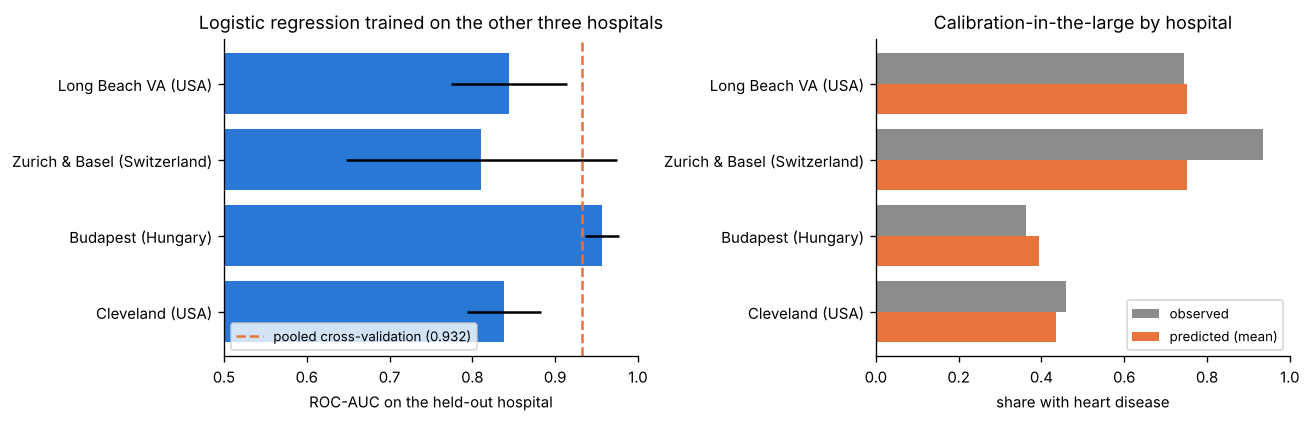

In [7]:
rows = []
for site, v in a1["leave_one_hospital_out"].items():
    for m, r in v["models"].items():
        rows.append({"held-out hospital": site, "n": v["n"], "disease rate": v["disease_rate"], "model": m, "ROC-AUC": r["auc"],
                     "mean predicted": r["mean_predicted"], "calibration intercept": r["calibration_intercept"], "accuracy": r["accuracy_at_0.5"]})
display(pd.DataFrame(rows).round(3))
display(Image(filename=str(FIG / "part1_external.png")))

**Reading this**
- **Hungary:** ROC-AUC about 0.96.
- **Cleveland:** it drops to 0.79–0.84.
- **Switzerland:** 0.73–0.81. At this hospital 93% of patients have heart disease, but the model predicts about 73%, so it is badly miscalibrated (intercept +2.2).
- **Logistic regression is the most robust** of the four on the two hardest hospitals, despite ranking mid-table in pooled cross-validation.

The pooled cross-validation score (about 0.93) overstates how well the model transfers to a new hospital.

### 1f. Association tests, adjusted odds ratios and SHAP

In [8]:
display(pd.DataFrame(a1["association_tests"]).round(4))
display(pd.DataFrame(a1["odds_ratios"]).round(3))
print("exact SHAP (logistic), mean |log-odds|:", {k: round(v, 3) for k, v in a1["shap_logistic"]["mean_abs_shap"].items()})

,feature,test,p,effect,effect_size,p_holm
0,Sex,chi-square,0.0000,Cramér's V,0.3028,0.0000
1,ChestPainType,chi-square,0.0000,Cramér's V,0.5404,0.0000
2,RestingECG,chi-square,0.0042,Cramér's V,0.1091,0.0042
3,ExerciseAngina,chi-square,0.0000,Cramér's V,0.4920,0.0000
4,ST_Slope,chi-square,0.0000,Cramér's V,0.6227,0.0000
5,FastingBS,chi-square,0.0000,Cramér's V,0.2647,0.0000
6,Age,Mann-Whitney U,0.0000,P(diseased > healthy),0.6681,0.0000
7,RestingBP (zeros as missing),Mann-Whitney U,0.0005,P(diseased > healthy),0.5670,0.0014
8,Cholesterol (zeros as missing),Mann-Whitney U,0.0017,P(diseased > healthy),0.5664,0.0034
9,MaxHR,Mann-Whitney U,0.0000,P(diseased > healthy),0.2650,0.0000


,feature,odds_ratio,ci,p
0,Age (per 10),1.197,"[0.9207172209861095, 1.5559633947329916]",0.179
1,RestingBP (per 10),1.062,"[0.9336822102267023, 1.2087458422937973]",0.358
2,Cholesterol (per 40),1.090,"[0.9347121204926921, 1.2710619440321251]",0.272
3,FastingBS,2.595,"[1.4789571358281233, 4.554098232388828]",0.001
4,MaxHR (per 10),0.979,"[0.883376382532156, 1.0840409231695205]",0.678
5,Oldpeak (per 1),1.486,"[1.1736367703420947, 1.88260689731028]",0.001
6,Cholesterol_missing,5.719,"[2.910739960210325, 11.238390827417254]",0.000
7,Sex_M,4.697,"[2.683855680780534, 8.221847154546731]",0.000
8,ChestPainType_ATA,0.174,"[0.09106001295915207, 0.33327600253028955]",0.000
9,ChestPainType_NAP,0.197,"[0.1154886631893786, 0.33576011905961545]",0.000


exact SHAP (logistic), mean |log-odds|: {'ST_Slope': 1.094, 'ChestPainType': 0.787, 'Cholesterol': 0.512, 'Sex': 0.469, 'ExerciseAngina': 0.42, 'Oldpeak': 0.348, 'FastingBS': 0.336, 'Age': 0.13, 'RestingBP': 0.084, 'RestingECG': 0.067, 'MaxHR': 0.065}


After adjustment, the "cholesterol missing" flag has an odds ratio of about 5.7. That is the hospital effect again, not biology. ST slope, chest-pain type, sex and exercise angina carry most of the signal.

---
## Part 2: 10-year cardiovascular death in US adults (NHANES + National Death Index)

### 2a. Cohort and data validation

In [9]:
cb = R("cohort_build")
display(pd.DataFrame(cb["steps"]))
c = pd.read_csv(ROOT / "data" / "nhanes_cvd_cohort.csv.gz")
print(c.groupby("split").agg(people=("seqn", "size"), cycles=("cycle", lambda s: sorted(s.unique().tolist())), cvd_deaths_10y=("cvd_death_10y", "sum"),
                             median_followup_years=("months", lambda s: round(s.median() / 12, 1))))
print("mortality-file layout checks (share passing):", {k: min(v.values()) for k, v in cb["lmf_checks"].items()})

,step,removed,remaining
0,"adults in NHANES 1999-2018 (all ages, interviewed)",0,59204
1,examined at the mobile examination centre,2837,56367
2,aged 40-79,25663,30704
3,not pregnant,31,30673
4,eligible for mortality linkage,70,30603
5,no self-reported heart disease or stroke (prevention population),4314,26289
6,"core risk factors measured (cholesterol, HDL, BP, BP treatment, smoking, diabetes)",2401,23888
7,follow-up time recorded,0,23888


               people  ... median_followup_years
split                  ...                      
development      6081  ...                  16.9
recent          13083  ...                   5.8
temporal_test    4724  ...                  12.3

[3 rows x 4 columns]
mortality-file layout checks (share passing): {'1999': 0.9994029850746269, '2001': 0.999384236453202, '2003': 1.0, '2005': 1.0, '2007': 1.0, '2009': 1.0, '2011': 1.0, '2013': 1.0, '2015': 1.0, '2017': 1.0}


In [10]:
from cvd_risk.experiments import RANGES
val = pd.DataFrame({v: {"n": c[v].notna().sum(), "missing": c[v].isna().mean(), "in plausible range": c[v].dropna().between(*RANGES[v]).mean(),
                        "min": c[v].min(), "median": c[v].median(), "max": c[v].max()} for v in RANGES}).T
display(val.round(3))
q2 = R("quality")
print("uniqueness:", q2["uniqueness"])
display(pd.Series(q2["consistency"], name="share passing").to_frame().style.format("{:.2%}"))
print("cross-checks:", q2["accuracy_cross_checks"])
print("excluded for missing core risk factors:", json.dumps(q2["excluded_for_missing_core"], indent=1))
print("class balance (10-year CVD death):", q2["class_balance"])

,n,missing,in plausible range,min,median,max
sbp,23888.0,0.000,1.0,64.670,125.30,256.0
dbp,23805.0,0.003,1.0,10.000,73.33,132.0
tchol,23888.0,0.000,1.0,75.000,201.00,813.0
hdl,23888.0,0.000,1.0,6.000,51.00,226.0
hba1c,23857.0,0.001,1.0,2.000,5.60,18.8
bmi,23634.0,0.011,1.0,13.180,28.34,130.2
waist,23224.0,0.028,1.0,59.400,99.30,177.9
egfr,21638.0,0.094,1.0,2.816,92.43,179.7
pir,21768.0,0.089,1.0,0.000,2.49,5.0
age,23888.0,0.000,1.0,40.000,56.00,79.0


uniqueness: {'rows': 23888, 'duplicate_person_ids': 0, 'ids_shared_across_cycles': 0, 'duplicate_rows_all_columns': 0}


,share passing
diastolic < systolic,100.00%
HDL < total cholesterol,100.00%
not both current and former smoker,100.00%
derivation: HbA1c >= 6.5% always coded as diabetes,100.00%
CVD death implies death,100.00%
deaths have a recorded cause,100.00%
follow-up time not negative,100.00%
deaths occur within the follow-up of survivors (same cycle),100.00%


cross-checks: {'median HbA1c, diabetes vs not': [7.0, 5.5], 'median SBP, BP-treated vs not': [132.0, 122.7], 'BMI-waist correlation': 0.8865973410511806}
excluded for missing core risk factors: {
 "n_excluded": 2401,
 "share": 0.09133097493248127,
 "smd_excluded_vs_included": {
  "age": 3.618644121153233e-05,
  "female": 0.07486433662028956,
  "race_black": 0.30900520154214134,
  "race_hispanic": -0.08606157717700715,
  "pir": -0.21384414061876952,
  "bmi": 0.03805524061947609,
  "sbp": 0.18295505652063634
 },
 "cvd_death_10y_excluded": 0.04888888888888889,
 "cvd_death_10y_included": 0.03816556548775748
}
class balance (10-year CVD death): {'development': {'n': 6081, 'cvd_death_10y_rate': 0.030915967768459136}, 'temporal_test': {'n': 4724, 'cvd_death_10y_rate': 0.0281541066892464}}


**Uniqueness, consistency and accuracy**
- One row per person; no person ID is reused across cycles.
- Every internal consistency check passes: diastolic below systolic, HDL below total cholesterol, every cardiovascular death recorded as a death with a cause, and no death after the end of follow-up.
- The cross-checks behave as they should. People with diabetes have a median HbA1c of 7.0% against 5.5%. Treated hypertensives still have higher systolic pressure (132 vs 123). BMI and waist correlate at 0.89, which is why the model treats them as overlapping (2g).

**Class balance:** only about 3% of people have the outcome, so this is a strongly imbalanced problem. Section 2e tests what to do about it.

**Validity and completeness**
- All core risk factors are complete by construction.
- The partially missing predictors are eGFR (about 9%, because creatinine wasn't measured on everyone), the income-to-poverty ratio (about 9%) and statin use (about 12%). They're imputed inside each training fold, with missing-value flags.
- The 9% excluded for missing core risk factors are more often Black and lower-income, and have a slightly higher death rate. That's a mild selection bias to keep in mind when generalising.

### 2b. Exploratory analysis

,test,p,effect_P(event>non-event),p_holm,risk_ratio
age,Mann-Whitney U,0.0,0.752423,0.0,NaN
sbp,Mann-Whitney U,0.0,0.661647,0.0,NaN
dbp,Mann-Whitney U,0.000129,0.436894,0.001287,NaN
tchol,Mann-Whitney U,0.87189,0.502638,1.0,NaN
hdl,Mann-Whitney U,0.051304,0.468127,0.205215,NaN
hba1c,Mann-Whitney U,0.0,0.607392,0.0,NaN
bmi,Mann-Whitney U,0.976695,0.499507,1.0,NaN
egfr,Mann-Whitney U,0.0,0.32385,0.0,NaN
pir,Mann-Whitney U,0.0,0.371024,0.0,NaN
female,chi-square,0.000652,NaN,0.005871,0.68085


,unweighted,survey_weighted
smoker,0.2112,0.2104
diabetes,0.1582,0.1087
bp_treated,0.2907,0.2503
female,0.5096,0.5236
race_black,0.1972,0.0936
cvd_death_10y,0.0297,0.0202


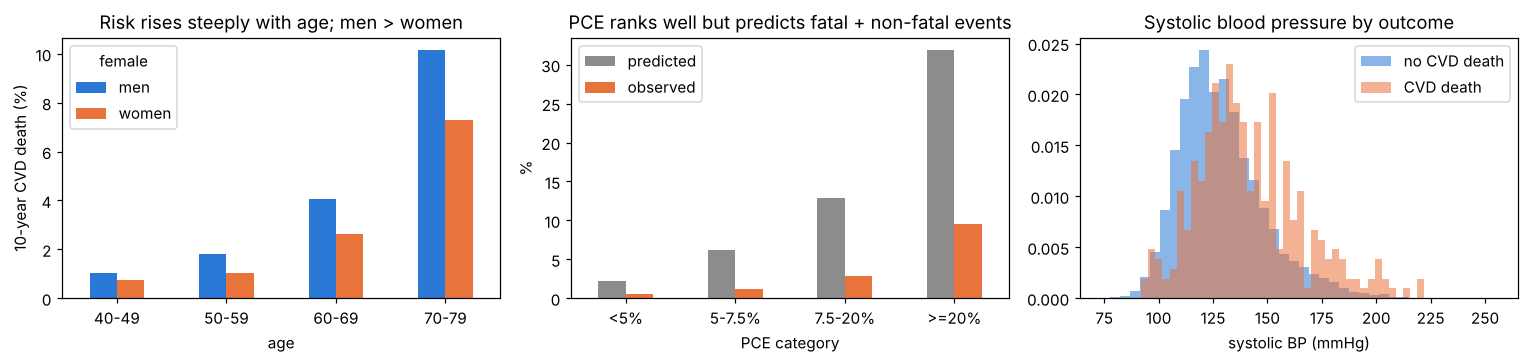

In [11]:
b = c[c.split.isin(["development", "temporal_test"])].copy()
b["age_band"] = pd.cut(b.age, [39, 49, 59, 69, 79], labels=["40-49", "50-59", "60-69", "70-79"])
b["pce"] = pce.risk_10y(b)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
b.groupby(["age_band", "female"], observed=True).cvd_death_10y.mean().unstack().rename(columns={0: "men", 1: "women"}).mul(100).plot.bar(ax=ax[0], color=["#2a78d6", "#e8743b"], rot=0)
ax[0].set(ylabel="10-year CVD death (%)", xlabel="age", title="Risk rises steeply with age; men > women")
cat = pd.cut(b.pce, [0, .05, .075, .2, 1], labels=["<5%", "5-7.5%", "7.5-20%", ">=20%"])
g = b.groupby(cat, observed=True).agg(predicted=("pce", "mean"), observed=("cvd_death_10y", "mean")).mul(100)
g.plot.bar(ax=ax[1], color=["#8c8c8c", "#e8743b"], rot=0)
ax[1].set(ylabel="%", xlabel="PCE category", title="PCE ranks well but predicts fatal + non-fatal events")
for y, col in ((0, "#2a78d6"), (1, "#e8743b")):
    ax[2].hist(b.loc[b.cvd_death_10y == y, "sbp"], bins=40, density=True, alpha=0.55, color=col, label=["no CVD death", "CVD death"][y])
ax[2].set(xlabel="systolic BP (mmHg)", title="Systolic blood pressure by outcome"); ax[2].legend()
plt.tight_layout(); plt.show()
e = R("eda")
display(pd.DataFrame(e["univariable_tests"]).T.round(4))
display(pd.DataFrame(e["weighted_vs_unweighted"]).T.round(4))

**What the exploration shows**
- About 3% of people died of cardiovascular disease within 10 years, and roughly three times as many died of other causes (a competing risk).
- The Pooled Cohort Equations rank people well: observed death rates rise steadily across the PCE categories. But their absolute risks are several times higher than observed death rates. That's expected, because they predict fatal *and* non-fatal heart attacks and strokes.
- **Survey weights matter for prevalence but not for ranking.** Unweighted, the sample over-represents Black and diabetic adults (NHANES oversamples them by design), so weighted estimates are reported alongside.

### 2c. Feature engineering (from raw NHANES variables to model inputs)

In [12]:
adults = pd.read_csv(ROOT / "data" / "nhanes_adults_harmonised.csv.gz", usecols=["seqn", "cycle", "diabetes", "hba1c", "creatinine", "egfr", "age", "female", "n_bp_readings", "smoker", "former_smoker"])
x = adults[adults.seqn.isin(c.seqn)]
undiag = ((c.hba1c >= 6.5) & (c.diabetes == 1)).mean()
print(f"diabetes: {c.diabetes.mean():.1%} overall; HbA1c >= 6.5% among them: {undiag:.1%} of the cohort")
print("blood-pressure readings averaged per person:", x.n_bp_readings.value_counts().sort_index().to_dict())
print("smoking status:", {"current": c.smoker.mean().round(3), "former": c.former_smoker.mean().round(3)})
from cvd_risk.nhanes import egfr_ckd_epi_2021
print("eGFR (CKD-EPI 2021, race-free) at creatinine 0.8 / 1.0 / 1.5 mg/dL for a 60-year-old man:",
      egfr_ckd_epi_2021(pd.Series([0.8, 1.0, 1.5]), pd.Series([60] * 3), pd.Series([0] * 3)).round(1).tolist())

diabetes: 18.4% overall; HbA1c >= 6.5% among them: 13.6% of the cohort
blood-pressure readings averaged per person: {1: 449, 2: 759, 3: 22680}
smoking status: {'current': np.float64(0.197), 'former': np.float64(0.281)}
eGFR (CKD-EPI 2021, race-free) at creatinine 0.8 / 1.0 / 1.5 mg/dL for a 60-year-old man: [101.3, 86.2, 53.0]


**Feature-engineering decisions**

| Feature | How it is built | Why |
|---|---|---|
| Blood pressure | Mean of the 1–4 examination readings; diastolic readings of 0 ("heard to zero") excluded | One reading is noisy; 0 is not a pressure |
| Diabetes | Told by a doctor, *or* on insulin or tablets, *or* HbA1c ≥ 6.5% | Self-report alone misses undiagnosed diabetes |
| Smoking | Current = ≥100 cigarettes in life and smokes now; former = ≥100 cigarettes, not now | The PCE definition |
| Kidney function | eGFR by CKD-EPI 2021 (race-free) from creatinine, with CDC's recalibration for 1999–2000 and 2005–2006 | Assay changed between cycles |
| Age | Spline (non-linear) in the logistic model | Risk rises faster than linearly with age |
| Missing values | Median imputation plus a missing flag, fitted inside each training fold | No information from validation folds |
| **Not used** | Death-certificate diabetes and hypertension flags from the mortality file | Recorded after death: leakage (2h) |

### 2d. Model screen (LazyPredict-style, done properly)
Eighteen candidates (17 fitted models, including XGBoost and LightGBM run on Colab on the same folds, plus the published, unfitted equations), 5×5 repeated stratified cross-validation on the development cohort only, all preprocessing inside the folds. p-values compare each model with the best using a corrected resampled t-test with Holm adjustment.

,model,cv_auc,cv_auc_sd,cv_pr_auc,cv_brier,p_vs_best_holm
0,Random forest,0.7946,0.0378,0.1457,0.0284,1.0000
1,"Logistic regression (L1, C=0.05)",0.7903,0.0312,0.1522,0.0285,1.0000
2,"Pooled Cohort Equations (published, not refitted)",0.7895,0.0246,0.1527,0.0422,1.0000
3,"Logistic regression (all features, age spline)",0.7883,0.0354,0.1548,0.0285,1.0000
4,"PCE variables, refitted",0.7865,0.0290,0.1383,0.0285,1.0000
5,XGBoost (3.4.1),0.7858,0.0378,0.1489,0.0285,1.0000
6,Extra trees,0.7838,0.0384,0.1289,0.0288,1.0000
7,LightGBM (4.6.0),0.7817,0.0368,0.1554,0.0286,1.0000
8,AdaBoost,0.7817,0.0290,0.1347,0.1086,1.0000
9,Histogram gradient boosting,0.7816,0.0356,0.1418,0.0286,1.0000


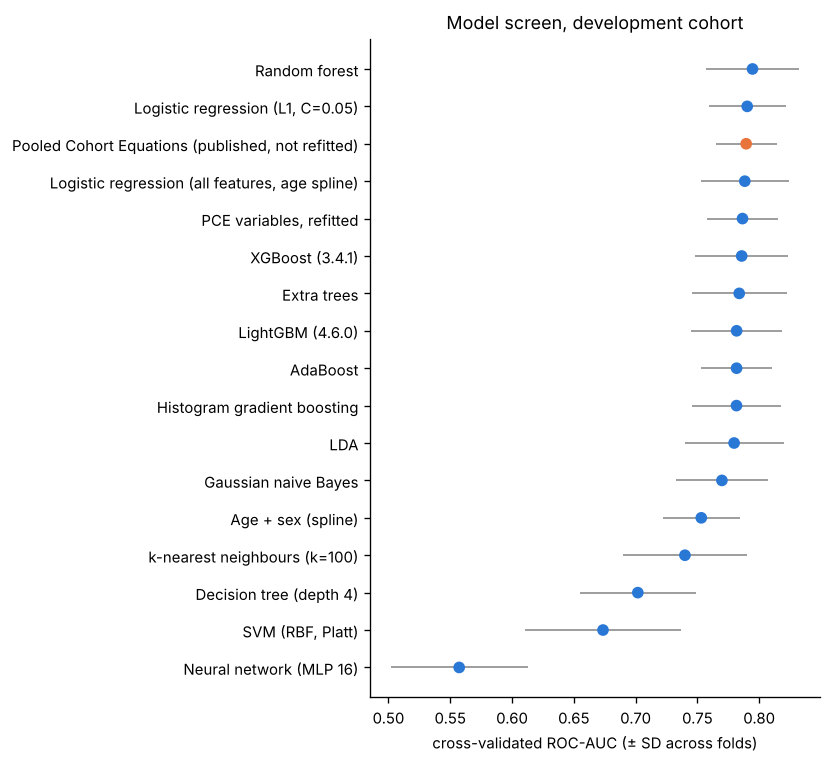

In [13]:
bm = R("benchmark")
display(pd.DataFrame(bm["table"])[["model", "cv_auc", "cv_auc_sd", "cv_pr_auc", "cv_brier", "p_vs_best_holm"]].round(4))
display(Image(filename=str(FIG / "benchmark.png")))

**Reading this**
- **The top eleven models span only 0.015 ROC-AUC** (0.780–0.795, including XGBoost 0.786 and LightGBM 0.782), and after Holm correction none differs significantly from the best (random forest, 0.795).
- **The published Pooled Cohort Equations score 0.790 without ever seeing this data.**
- With about 190 deaths, cross-validation can't even separate the best model from age and sex alone (0.753, Holm p = 0.38). Small event counts make model rankings fragile; that's why the final comparison is made once, on a separate test period.
- **Clearly worse:** the depth-4 decision tree, the SVM and the neural network.

### 2e. Class imbalance (about 3% events)

In [14]:
display(pd.DataFrame(R("imbalance")).T.round(4))

,cv_auc,cv_pr_auc,cv_brier,cal_intercept,mean_predicted,observed
logistic / none,0.7874,0.1525,0.0285,-0.0035,0.0310,0.0309
logistic / class_weight,0.7791,0.1588,0.1742,-3.4468,0.3561,0.0309
logistic / oversample,0.7778,0.1562,0.1746,-3.4459,0.3563,0.0309
logistic / smote,0.7654,0.1299,0.1659,-3.4618,0.3243,0.0309
hgb / none,0.7736,0.1329,0.0288,0.1436,0.0272,0.0309
hgb / class_weight,0.7614,0.1243,0.1052,-2.7463,0.2496,0.0309
hgb / oversample,0.7353,0.1194,0.0456,-1.3973,0.0841,0.0309
hgb / smote,0.7014,0.0871,0.0521,-1.6013,0.1049,0.0309


**Reading this**
- **Class weights, oversampling and SMOTE all lower ROC-AUC.** For logistic regression it falls from 0.787 to 0.765–0.779.
- **PR-AUC barely moves:** class weights 0.159 vs 0.152, SMOTE worse at 0.130.
- **They inflate the average predicted risk from the true 3.1% to 32–36%.** A risk score whose "30%" means 3% is unusable for patient conversations or treatment thresholds.
- For a risk score, the right way to handle imbalance is to keep the data as it is and choose the decision threshold explicitly.

### 2f. Selection and temporal validation (fit on 1999–2004, test once on 2005–2008)

{'hgb_minus_logistic_auc': -0.002081504753124053, 'p_corrected_t': 0.8746803102823891, 'chosen': 'logistic', 'rule': 'choose gradient boosting only if it beats logistic regression by > 0.005 AUC with p < 0.05 (corrected resampled t-test)'}


,label,auc,pr_auc,brier,cal_intercept,cal_slope,o_e
age_sex,Age + sex,0.759417,0.086003,0.026463,-0.070127,1.079166,0.936056
pce_refit,"PCE variables, refitted",0.805106,0.10287,0.02635,-0.038581,1.008414,0.965048
logistic,Logistic regression (all features),0.822359,0.140169,0.025821,0.008701,0.997634,1.007919
hgb,Gradient boosting (all features),0.797917,0.111141,0.026167,-0.034626,1.112468,0.968227
pce,Pooled Cohort Equations (published),0.798958,0.09621,0.040063,-1.589199,0.896275,0.259421
pce_recalibrated,"PCE, recalibrated to CVD death",0.798958,0.09621,0.026466,-0.037033,0.957161,0.9664


,diff,ci,p,p_holm
age_sex,-0.039541,"[-0.0678073536086203, -0.011275127152201404]",0.00611,0.024439
pce_refit,0.006148,"[-0.005834834391543583, 0.018130876173192253]",0.314602,0.629203
logistic,0.023401,"[0.00078211945896111, 0.04602079503703694]",0.042584,0.127751
hgb,-0.001041,"[-0.02827429942161274, 0.026192750526504265]",0.940291,0.940291


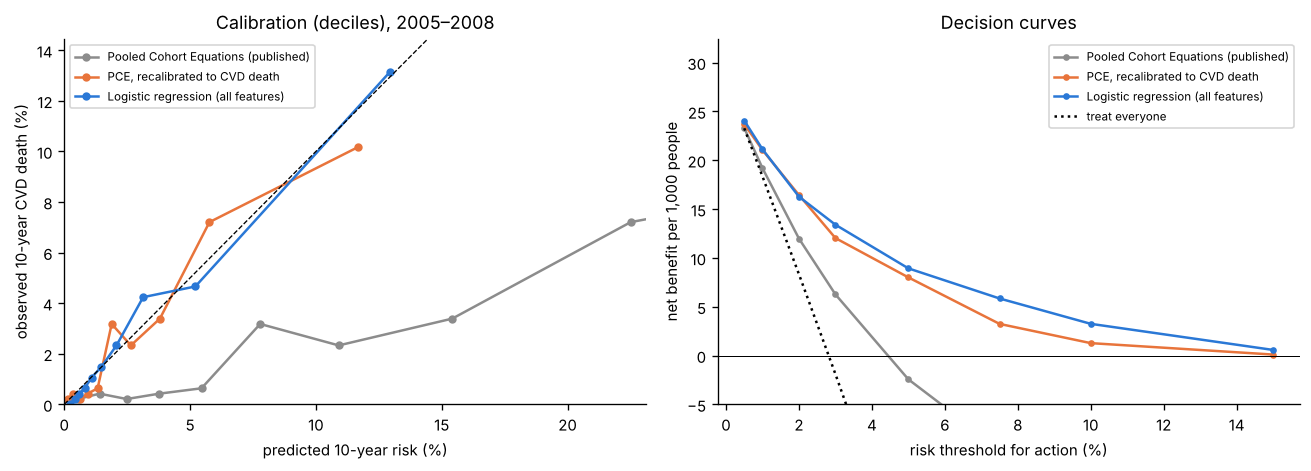

In [15]:
sel = R("select"); print(sel["comparison"])
t = R("temporal")
tab = pd.DataFrame({k: {m: v[m] for m in ["label", "auc", "pr_auc", "brier", "cal_intercept", "cal_slope", "o_e"]} for k, v in t["models"].items()}).T
display(tab)
display(pd.DataFrame(t["vs_pce"]).T[["diff", "ci", "p", "p_holm"]])
display(Image(filename=str(FIG / "temporal_validation.png")))

**The main result (fit on 1999–2004, tested once on 2005–2008: 4,724 people, 133 cardiovascular deaths)**

| | ROC-AUC (95% CI) | Observed / expected |
|---|---|---|
| Published Pooled Cohort Equations | 0.799 (0.765–0.833) | **0.26**: predicts about 4× too many deaths |
| PCE recalibrated to CVD death | 0.799 (same ranking) | 0.97 |
| Age + sex only | 0.759 | 0.94 |
| **Logistic regression, all baseline features** | **0.822 (0.791–0.854)** | **1.01** (calibration slope 1.00) |
| Gradient boosting | 0.798 | 0.97 |

- **Calibration is where the real difference lies.** The published equations predict an average 10-year risk of 10.9% where 2.8% died of cardiovascular disease. That's expected rather than a flaw: they predict fatal *and* non-fatal events, while this outcome is death only. A two-parameter recalibration fixes it; the new model is well calibrated without that step.
- **The ranking gain over the PCE is small and uncertain:** +0.023 ROC-AUC (95% CI +0.001 to +0.046, DeLong p = 0.043; **Holm-adjusted p = 0.13**). Against the same nine PCE variables refitted to this outcome, it is +0.017 (p = 0.07). The honest summary: the extra measurements (waist, kidney function, income, education) add little discrimination.
- **The gain shows most at the top of the risk distribution.** Flagging the highest-risk 10% captures 47% of cardiovascular deaths with the new model, against 36% with the PCE.
- **Decision curves:** at a 5% action threshold, the new model gives 8.9 net true positives per 1,000 people, against 8.0 for the recalibrated PCE. The uncorrected PCE gives −2.4, worse than treating nobody, because it overestimates risk.
- **Gradient boosting was significantly worse than logistic regression** on the test period (−0.024, p = 0.007). The pre-registered selection rule had already chosen logistic regression from cross-validation.

### 2g. Survival analysis on 2009–2018 (incomplete follow-up)

In [16]:
sv = R("survival")
display(pd.DataFrame(sv["hazard_ratios"]).round(3))
for k, v in sv["evaluation"].items():
    print(k, {m: (round(v[m], 4) if isinstance(v[m], float) else v[m]) for m in ["n", "cvd_deaths", "c_index_cox", "c_index_pce", "c_index_age", "overall_predicted", "overall_observed_km", "horizon_months"]})
    display(pd.DataFrame(v["calibration_by_quintile"]).round(4))

,feature,hr_per_sd,ci,sd
0,age,2.324,"[2.0284498462460006, 2.6629378797005985]",11.240
1,female,0.806,"[0.7186794109656889, 0.9034247208415286]",0.500
2,race_black,1.079,"[0.979365564943712, 1.1895093583871656]",0.391
3,race_hispanic,0.820,"[0.7312825678228735, 0.9190882236102245]",0.447
4,race_other,0.909,"[0.8051465961900932, 1.026250010102307]",0.169
5,tchol,0.952,"[0.8642621079354157, 1.048937491326026]",41.254
6,hdl,1.092,"[0.983078041775238, 1.2119554601890152]",16.007
7,sbp,1.224,"[1.1118833807117654, 1.346672117462327]",20.439
8,dbp,0.952,"[0.8721829983107712, 1.0399614252632001]",11.569
9,bp_treated,1.221,"[1.1147128982390246, 1.3383427730916102]",0.447


temporal test 2005-2008 {'n': 4724, 'cvd_deaths': 199, 'c_index_cox': 0.8227, 'c_index_pce': 0.8041, 'c_index_age': 0.7679, 'overall_predicted': 0.0342, 'overall_observed_km': 0.0294, 'horizon_months': 120}


,quintile,predicted,observed_km
0,1,0.0031,0.0011
1,2,0.0069,0.0075
2,3,0.0138,0.0098
3,4,0.0307,0.0323
4,5,0.1166,0.1050


recent 2009-2018 {'n': 13083, 'cvd_deaths': 174, 'c_index_cox': 0.8065, 'c_index_pce': 0.7839, 'c_index_age': 0.7306, 'overall_predicted': 0.0101, 'overall_observed_km': 0.0093, 'horizon_months': 60}


,quintile,predicted,observed_km
0,1,0.0009,0.0004
1,2,0.0021,0.0031
2,3,0.0042,0.0037
3,4,0.0090,0.0093
4,5,0.0344,0.0318


- **The survival model works on the newest data.** It's a cause-specific Cox model (deaths from other causes treated as censored), fitted on 1999–2004. On 2009–2018 (13,083 people, 174 cardiovascular deaths, median 5.8 years of follow-up) its C-index is **0.807**, against 0.784 for the PCE and 0.731 for age alone.
- **It is calibrated on the newest data:** predicted 5-year risk 1.01% against 0.93% observed (Kaplan–Meier), and close in every quintile.
- **Hazard ratios** (per standard deviation): age 2.3, smoking 1.3, systolic BP 1.2, BP treatment 1.2.
- **Waist (1.36) and BMI (0.80) point in opposite directions** because they're strongly correlated. Each is adjusted for the other, so neither coefficient should be read causally.

### 2h. Leakage and design checks

In [17]:
lk = R("leakage")
display(pd.DataFrame({k: v for k, v in lk.items() if k != "note_prior_cvd"}).T.round(4)); print(lk.get("note_prior_cvd"))

,auc,pr_auc
"correct (baseline variables, temporal split)",0.8224,0.1402
+ death-certificate diabetes & hypertension flags (recorded after death),0.8403,0.1807
random split instead of temporal (same features),0.7966,0.1326
+ people who already had heart disease or stroke (prior CVD as a feature),0.8321,0.1613


{'share_with_prior_cvd': 0.15523015299757043, 'event_rate_prior_cvd': 0.1751269035532995, 'event_rate_no_prior_cvd': 0.03816556548775748}


- **Death-certificate flags:** adding the mortality file's diabetes and hypertension flags (recorded *after* death) raises ROC-AUC from 0.822 to 0.840 and PR-AUC from 0.140 to 0.181. That gain is fake: the model would be partly learning who died.
- **People who already had heart disease or stroke:** including them (15.5% of the eligible adults, with a 17.5% death rate against 3.8%) raises ROC-AUC to 0.832. It answers a different question; a prevention score is for people without disease.
- **A random split instead of a temporal one** gave 0.797, *lower* than the temporal test. So there's no sign here that the temporal design hides optimism. Different people simply land in the test set.

### 2i. Subgroups and explanations

,n,events,pce_auc,logistic_auc,pce_recalibrated_o_e,logistic_o_e
women,2423.0,58.0,0.823,0.851,1.067,1.099
men,2301.0,75.0,0.769,0.791,0.901,0.947
non-Hispanic Black,983.0,34.0,0.812,0.830,1.034,0.970
Hispanic,1211.0,21.0,0.742,0.760,0.650,0.712
other (mostly non-Hispanic White),2530.0,78.0,0.809,0.834,1.077,1.157
age 40-59,2753.0,30.0,0.760,0.815,0.909,1.037
age 60-79,1971.0,103.0,0.716,0.744,0.984,1.000
diabetes,799.0,37.0,0.698,0.745,0.715,0.840
no diabetes,3925.0,96.0,0.825,0.836,1.117,1.092


exact SHAP (logistic), mean |log-odds|: {'age': 0.416, 'waist': 0.348, 'egfr': 0.235, 'bp_treated': 0.231, 'bmi': 0.229, 'female': 0.227, 'pir': 0.217, 'smoker': 0.211, 'sbp': 0.192, 'tchol': 0.096, 'dbp': 0.082, 'former_smoker': 0.079, 'diabetes': 0.066, 'hba1c': 0.062, 'lipid_treated': 0.059, 'race_other': 0.042, 'education_college': 0.042, 'race_black': 0.025, 'hdl': 0.023, 'race_hispanic': 0.014}
additivity error: 1.4210854715202004e-14


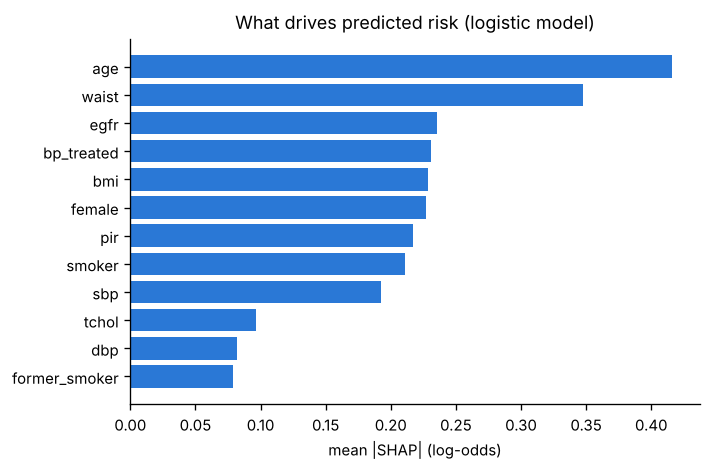

In [18]:
display(pd.DataFrame(R("subgroups")).T.round(3))
ex = R("explain")
print("exact SHAP (logistic), mean |log-odds|:", {k: round(v, 3) for k, v in ex["logistic"]["mean_abs_shap"].items()})
print("additivity error:", ex["logistic"]["additivity_max_error"])
display(Image(filename=str(FIG / "shap.png")))

- **Subgroups:** discrimination is good in women (0.85) and lower in men (0.79). It's also lower within the 60–79 age band (0.74), because age, the strongest predictor, varies less there.
- **Calibration differs by group:**
  - **Hispanic adults:** both models over-predict (observed/expected 0.71 for the new model, 0.65 for the recalibrated PCE), consistent with the well-known lower cardiovascular mortality in this group.
  - **People with diabetes:** both models also over-predict (0.84).
  - These are the groups where a deployed model would need group-specific recalibration.
- **SHAP (exact for logistic regression):** age dominates, followed by waist, kidney function, blood-pressure treatment, BMI, sex, income and smoking. Total cholesterol and HDL contribute little to predicting cardiovascular *death* in this population, once age, blood pressure and treatment are known. SHAP describes the model, not causation.

## Conclusions

**Part 1: the original heart-disease classifier**
1. The headline numbers rested on three errors:
   - a "test ROC-AUC" that was really balanced accuracy;
   - a test set reused to choose models;
   - a final cell trained on the wrong columns.
2. The data contains a hidden shortcut. "Cholesterol = 0" is a missing value that marks one hospital where 93% of patients had disease. It produced the medically backwards finding that heart patients have *lower* cholesterol.
3. Fifteen models score 0.89–0.93 in pooled cross-validation, and twelve of them (including XGBoost and LightGBM) can't be told apart statistically. Trained on three hospitals and tested on the fourth, ROC-AUC falls to 0.73–0.84 at Cleveland and Switzerland (Hungary 0.95–0.96, Long Beach 0.84–0.88), and calibration fails badly at the Swiss hospital. **Pooled cross-validation overstated how well the model transfers.**

**Part 2: 10-year cardiovascular death in US adults**
1. A logistic regression on routinely measured risk factors predicts 10-year cardiovascular death with ROC-AUC **0.822 (0.791–0.854)** on a later time period, and is **well calibrated** (observed/expected 1.01).
2. Against the clinical standard, the Pooled Cohort Equations (0.799):
   - the gain in ranking is **small and not robust** to multiple-comparison correction;
   - the clear gain is **calibration for this outcome**.
   The equations' 4× over-prediction comes from predicting a different, broader outcome, and recalibration fixes it.
3. More complex models (random forest, gradient boosting, neural network) **did not help**. With about 190 events, simplicity generalised better.
4. The cause-specific Cox model keeps its discrimination (C-index 0.807) and calibration on 2009–2018.
5. Known weak spots:
   - over-prediction for Hispanic adults and people with diabetes;
   - lower discrimination in men and in older adults;
   - a mild selection bias from complete-case analysis.

**Limitations.**
- The outcome is cardiovascular **death** only; NHANES has no non-fatal events.
- Statin use is self-reported.
- The public-use mortality files are perturbed for confidentiality.
- Evaluation is unweighted. It is a statement about this cohort, not a survey-weighted national estimate.

See `MODEL_CARD.md` for intended use.